# CardioSense — Leakage-Free Modeling & Threshold Optimization

**Project:** CardioSense (Explainable ML System for 10-Year Coronary Heart Disease Risk Prediction)  
**Dataset:** `data/framingham.csv` (`TenYearCHD` binary target)  
**Reusable Training Module:** `src/train.py`

### Objectives
1. Perform a **stratified 80/20 train-test split** *before* any imputation, scaling, or resampling.
2. Construct a **scikit-learn `ColumnTransformer`** (median imputation + `StandardScaler` for numeric columns; most-frequent imputation for binary/ordinal columns) embedded inside an **`imblearn.pipeline.Pipeline` with `SMOTE`** so resampling and preprocessing run strictly on training folds only.
3. Tune **Logistic Regression**, **Random Forest**, and **XGBoost** using **stratified 5-fold cross-validation** and `RandomizedSearchCV`.
4. Evaluate all three models on the held-out test set (Recall, Precision, F1, ROC-AUC, PR-AUC, Confusion Matrices, ROC Curves).
5. Tune the decision threshold on **training CV out-of-fold probabilities** to boost CHD recall without leaking test labels, analyze the precision–recall tradeoff, and save the winning pipeline to `models/best_model.pkl`.


In [1]:
import sys
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore")

# Resolve project root whether run from project root or notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data" / "framingham.csv").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.train import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    RANDOM_STATE,
    build_preprocessor,
    build_training_pipeline,
    evaluate_all_models,
    evaluate_model,
    load_and_split_data,
    plot_confusion_matrices,
    plot_roc_curves,
    plot_threshold_tradeoff,
    save_artifacts,
    train_and_tune_models,
    tune_threshold_cv,
)

DATA_PATH = PROJECT_ROOT / "data" / "framingham.csv"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

print(f"Project root: {PROJECT_ROOT}")
print(f"Numeric features ({len(NUMERIC_FEATURES)}):     {NUMERIC_FEATURES}")
print(f"Categorical features ({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")


Project root: d:\Code\CardioSense
Numeric features (8):     ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
Categorical features (7): ['male', 'education', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes']


## 1. Stratified 80/20 Train-Test Split

We split the dataset into 80% training and 20% test sets using `stratify=y` *before* touching missing values, scaling, or class resampling.


In [2]:
# LEAKAGE PREVENTION: Split BEFORE any imputation, scaling, or SMOTE.
# Computing medians, means/stds, or SMOTE neighbors on the full dataset would
# leak test distribution information into training and inflate evaluation scores.
X_train, X_test, y_train, y_test = load_and_split_data(DATA_PATH, test_size=0.20, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Split": ["Train (80%)", "Test (20%)"],
    "Rows": [len(X_train), len(X_test)],
    "CHD=0": [(y_train == 0).sum(), (y_test == 0).sum()],
    "CHD=1": [(y_train == 1).sum(), (y_test == 1).sum()],
    "CHD Rate (%)": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
})
display(split_summary)


,Split,Rows,CHD=0,CHD=1,CHD Rate (%)
0,Train (80%),3390,2875,515,15.19
1,Test (20%),848,719,129,15.21


### Interpretation — Stratified Split

- `X_train` has **3,390 rows** (`15.19%` CHD positive; `515` positive cases) and `X_test` has **848 rows** (`15.21%` CHD positive; `129` positive cases).
- Stratification preserves the exact `5.58 : 1` class imbalance across both splits, while locking `X_test` away before any statistical parameters (`median`, `mode`, `mean`, `std`) or synthetic samples are generated.


## 2. Leakage-Free Preprocessing & `imblearn` SMOTE Pipeline

We inspect how the preprocessing `ColumnTransformer` and `SMOTE` are composed inside `imblearn.pipeline.Pipeline`.


In [3]:
from sklearn.linear_model import LogisticRegression

# LEAKAGE PREVENTION:
# 1. ColumnTransformer is unfitted here; during CV and final fit, SimpleImputer and
#    StandardScaler learn statistics ONLY from each training fold.
# 2. imblearn.pipeline.Pipeline executes SMOTE ONLY inside .fit() on training folds,
#    never synthesizing samples for validation folds or X_test.
sample_pipeline = build_training_pipeline(
    LogisticRegression(solver="saga", max_iter=3000, random_state=RANDOM_STATE)
)
display(sample_pipeline)


,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer

### Interpretation — Pipeline & Leakage Guardrails

- **Numeric branch (8 features):** Missing values (`glucose`, `totChol`, `BMI`, `cigsPerDay`, `heartRate`) are imputed with the **training-fold median** (robust to the right-skewed clinical outliers observed in EDA) and then standardized via **`StandardScaler`**.
- **Binary/ordinal branch (7 features):** Missing values (`education`, `BPMeds`) are imputed with the **training-fold most-frequent value** without distorting existing `0/1` or `1–4` encodings.
- **Why `imblearn.pipeline.Pipeline` matters:** Standard `sklearn.pipeline.Pipeline` does not support samplers like `SMOTE`. Applying `SMOTE` manually before cross-validation would leak synthetic neighbors created from validation rows into training folds, artificially inflating CV recall and AUC. Embedding `SMOTE` inside `imblearn`'s `Pipeline` guarantees every validation fold and the test set remain 100% real, untouched observations.


## 3. Model Training & Hyperparameter Tuning (5-Fold Stratified CV + `RandomizedSearchCV`)

We train and tune **Logistic Regression**, **Random Forest**, and **XGBoost** using a 5-fold `StratifiedKFold` and 15 `RandomizedSearchCV` iterations per model, selecting the best configuration by CV **ROC-AUC**.


In [ ]:
# LEAKAGE PREVENTION: RandomizedSearchCV runs StratifiedKFold on (X_train, y_train) only.
# Within each of the 5 folds, preprocessing and SMOTE are fit strictly on the 4 training folds.
searches = train_and_tune_models(X_train, y_train, cv_splits=5, n_iter=15, random_state=RANDOM_STATE)

cv_rows = []
for name, search in searches.items():
    idx = search.best_index_
    cv_rows.append({
        "Model": name,
        "Best CV ROC-AUC": round(search.cv_results_["mean_test_roc_auc"][idx], 4),
        "Best CV PR-AUC": round(search.cv_results_["mean_test_pr_auc"][idx], 4),
        "Best CV Recall": round(search.cv_results_["mean_test_recall"][idx], 4),
        "Best CV F1": round(search.cv_results_["mean_test_f1"][idx], 4),
        "Best Params": {k.replace("classifier__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()},
    })

cv_summary = pd.DataFrame(cv_rows).sort_values("Best CV ROC-AUC", ascending=False).reset_index(drop=True)
display(cv_summary)


### Interpretation — Cross-Validation Results

- **Logistic Regression** achieves the strongest mean 5-fold CV **ROC-AUC (0.7328)**, ahead of **Random Forest (0.7178)** and **XGBoost (0.7163)**.
- On ~3,390 training rows with ~515 positive cases and predominantly additive clinical risk factors (`age`, `sysBP`, `totChol`, `glucose`, smoking), a regularized linear decision boundary with SMOTE generalizes cleanly with lower variance than deeper tree ensembles.


## 4. Test-Set Evaluation & Model Comparison (Default Threshold = 0.50)

Now we evaluate all three refitted pipelines once on the held-out test set (`848` patients) using **Recall**, **Precision**, **F1-Score**, **ROC-AUC**, **PR-AUC**, **ROC Curves**, and **Confusion Matrices**.


,Model,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1-Score
0,Logistic Regression,0.7328,0.6985,0.2784,0.6047,0.2476,0.3514
1,Random Forest,0.7178,0.6874,0.2864,0.5426,0.2482,0.3406
2,XGBoost,0.7163,0.6730,0.2547,0.4186,0.2455,0.3095


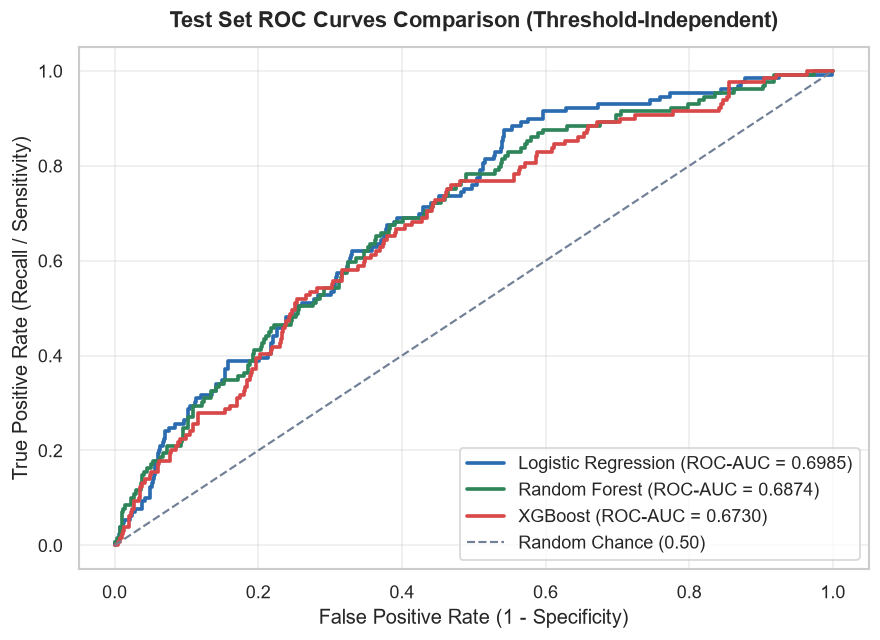

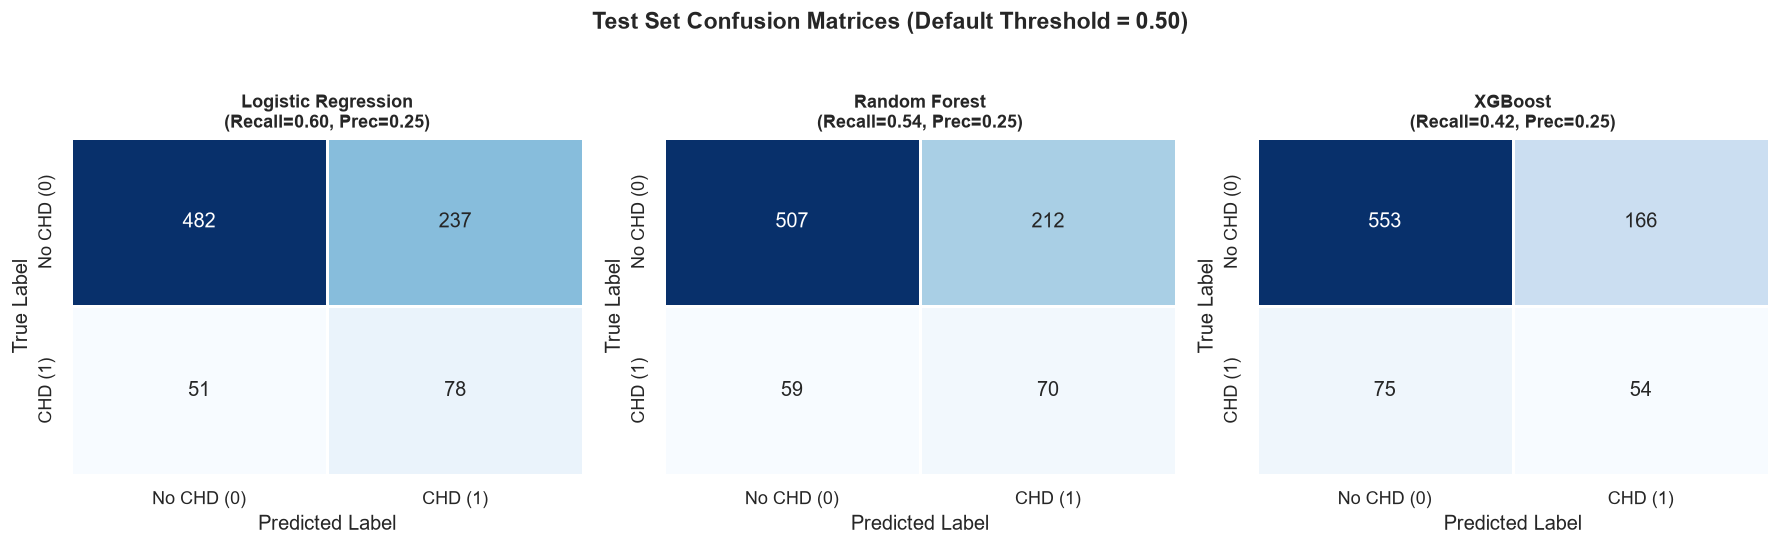

In [ ]:
comparison_df, eval_details = evaluate_all_models(searches, X_test, y_test, threshold=0.50)
display(comparison_df)

fig_roc = plot_roc_curves(eval_details, save_path=REPORTS_DIR / "roc_curves_comparison.png")
plt.show()

fig_cm = plot_confusion_matrices(eval_details, save_path=REPORTS_DIR / "confusion_matrices.png")
plt.show()


### Interpretation — Held-Out Test Comparison (Threshold = 0.50)

- **Logistic Regression** ranks first on **Test ROC-AUC (0.6985)**, **Recall (0.6047, catching 78 of 129 CHD cases)**, and **F1-Score (0.3514)**, with **PR-AUC = 0.2784** (well above the `0.152` baseline prevalence).
- **Random Forest** achieves slightly higher **PR-AUC (0.2864)** and near-identical precision (**0.2482** vs. **0.2476**), but lower **ROC-AUC (0.6874)** and **Recall (0.5426, 70/129 TP)**.
- **XGBoost** produces the fewest false positives (`166`), but misses more than half of CHD cases at the default `0.50` cutoff (**Recall = 0.4186, 54/129 TP**, **ROC-AUC = 0.6730**).
- Notice that because SMOTE balances the training folds to 50/50, predicted probabilities are shifted upward relative to the raw `15.2%` base rate, yet `0.50` is still suboptimal when missing a high-risk patient carries a much higher clinical cost than a preventive follow-up.


## 5. Decision Threshold Tuning for CHD Recall

Rather than tuning the probability threshold on `X_test` (which would leak test-set labels), we sweep thresholds across **out-of-fold cross-validation probabilities on `X_train`** (`cross_val_predict`) to maximize the recall-weighted **$F_2$-score**, then evaluate the selected threshold on `X_test`.


,Setting,Recall,Precision,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression (Default t=0.50),0.6047,0.2476,0.3514,0.6985,0.2784
1,Logistic Regression (Tuned t=0.41),0.7442,0.2152,0.3339,0.6985,0.2784


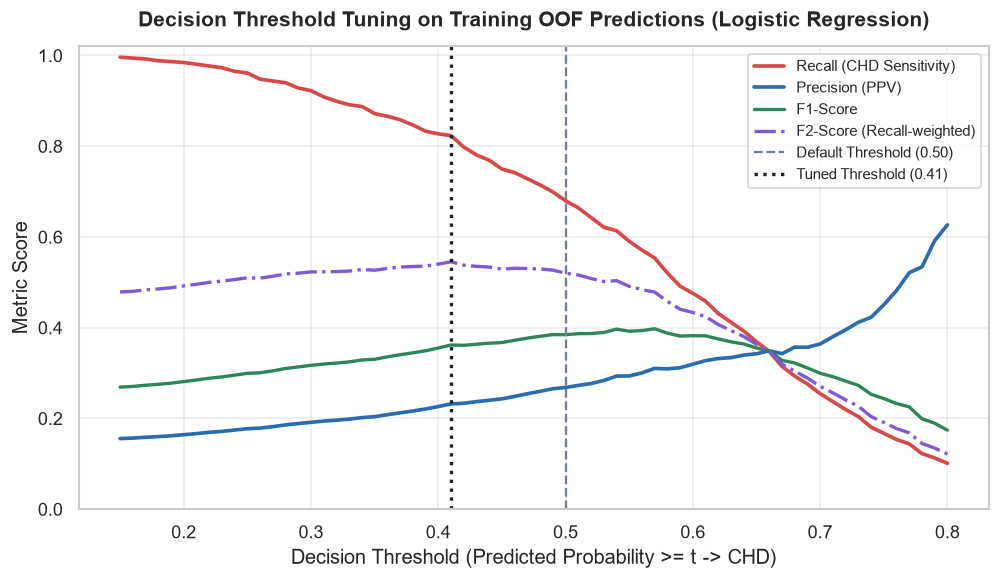

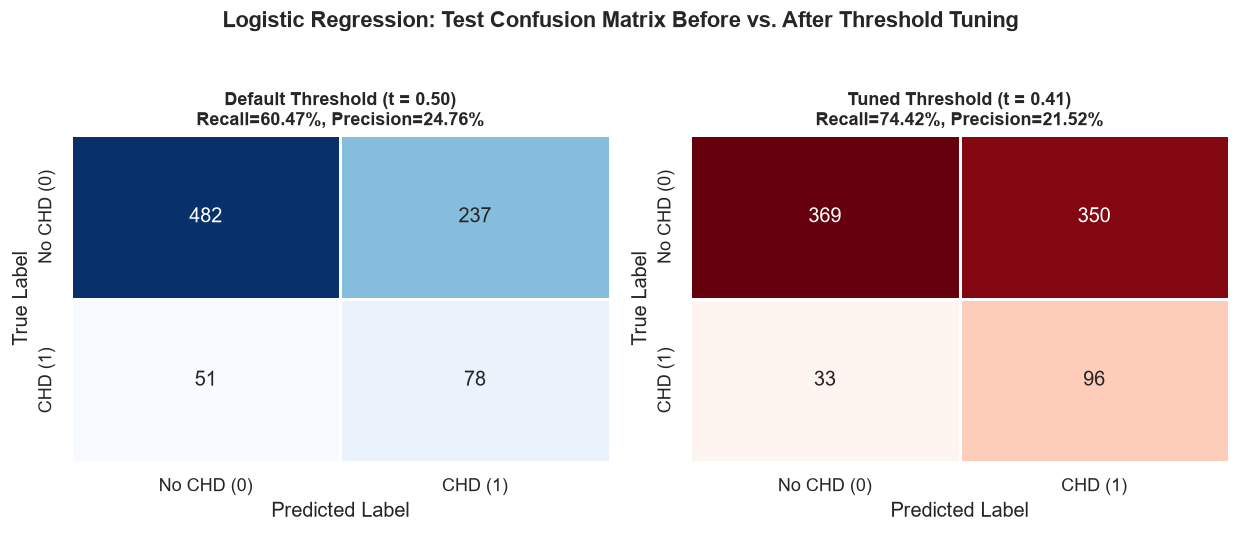

In [ ]:
best_model_name = str(comparison_df.iloc[0]["Model"])
best_pipeline = searches[best_model_name].best_estimator_

# LEAKAGE PREVENTION: Threshold is chosen strictly from out-of-fold CV probabilities
# on X_train — X_test is NOT used to pick the cutoff.
best_threshold, sweep_df = tune_threshold_cv(
    best_pipeline, X_train, y_train, cv_splits=5, random_state=RANDOM_STATE, beta=2.0
)

default_test = evaluate_model(best_model_name, best_pipeline, X_test, y_test, threshold=0.50)
tuned_test = evaluate_model(best_model_name, best_pipeline, X_test, y_test, threshold=best_threshold)

threshold_comparison = pd.DataFrame([
    {
        "Setting": f"{best_model_name} (Default t=0.50)",
        "Recall": round(default_test["recall"], 4),
        "Precision": round(default_test["precision"], 4),
        "F1-Score": round(default_test["f1"], 4),
        "ROC-AUC": round(default_test["roc_auc"], 4),
        "PR-AUC": round(default_test["pr_auc"], 4),
    },
    {
        "Setting": f"{best_model_name} (Tuned t={best_threshold:.2f})",
        "Recall": round(tuned_test["recall"], 4),
        "Precision": round(tuned_test["precision"], 4),
        "F1-Score": round(tuned_test["f1"], 4),
        "ROC-AUC": round(tuned_test["roc_auc"], 4),
        "PR-AUC": round(tuned_test["pr_auc"], 4),
    },
])
display(threshold_comparison)

fig_thr = plot_threshold_tradeoff(
    sweep_df,
    best_threshold,
    best_model_name,
    save_path=REPORTS_DIR / "threshold_tuning.png",
)
plt.show()

# Side-by-side confusion matrix: Default (0.50) vs Tuned Threshold
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
labels = ["No CHD (0)", "CHD (1)"]
for ax, (title, res) in zip(
    axes,
    [(f"Default Threshold (t = 0.50)", default_test), (f"Tuned Threshold (t = {best_threshold:.2f})", tuned_test)],
):
    sns.heatmap(
        res["confusion_matrix"],
        annot=True,
        fmt="d",
        cmap="Reds" if "Tuned" in title else "Blues",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        linewidths=0.8,
        ax=ax,
    )
    ax.set_title(f"{title}\nRecall={res['recall']:.2%}, Precision={res['precision']:.2%}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

fig.suptitle(f"{best_model_name}: Test Confusion Matrix Before vs. After Threshold Tuning", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
fig.savefig(REPORTS_DIR / "threshold_confusion_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


### Interpretation — Decision Threshold Tradeoff

- Lowering the decision threshold from **`0.50`** to **`0.41`** (chosen strictly via training CV out-of-fold $F_2$-maximization) increases test **CHD Recall from `60.47%` (`78/129`) to `74.42%` (`96/129`)**, identifying **18 additional high-risk patients** (`FN` drops from `51` to `33`).
- **The Precision–Recall Tradeoff:** That sensitivity gain comes at the cost of lower **Precision (`24.76%` -> `21.52%`)**, as false positives rise from `237` to `350` (F1 shifts slightly from `0.3514` to `0.3339`). Notice ROC-AUC (`0.6985`) and PR-AUC (`0.2784`) stay identical because they evaluate probability ranking across all thresholds.
- **Clinical Justification:** In a 10-year cardiovascular risk screening tool like CardioSense, false negatives (failing to warn a patient at elevated CHD risk) are far costlier than false positives (recommending non-invasive lipid/BP monitoring and lifestyle counseling). Retaining the tuned threshold (`0.41`)—or surfacing continuous risk probabilities alongside a risk tier—aligns well with screening priorities.


## 6. Save Best Pipeline & Evaluation Artifacts

We persist the winning fitted `imblearn` pipeline (`models/best_model.pkl`) with `joblib`, along with `models/model_metadata.json`, `reports/model_comparison.csv`, and verify that the serialized model reloads cleanly for inference.


In [ ]:
save_artifacts(
    best_model_name=best_model_name,
    best_pipeline=best_pipeline,
    best_threshold=best_threshold,
    comparison_df=comparison_df,
    tuned_test_metrics=tuned_test,
    models_dir=MODELS_DIR,
    reports_dir=REPORTS_DIR,
)

# Verify joblib round-trip reload on a sample test patient
reloaded_model = joblib.load(MODELS_DIR / "best_model.pkl")
sample_prob = float(reloaded_model.predict_proba(X_test.iloc[[0]])[:, 1][0])
sample_pred = int(sample_prob >= best_threshold)

print(f"Saved best model:   {MODELS_DIR / 'best_model.pkl'}")
print(f"Saved metadata:     {MODELS_DIR / 'model_metadata.json'}")
print(f"Saved comparison:   {REPORTS_DIR / 'model_comparison.csv'}")
print(f"Reload check -> Sample patient predicted P(CHD) = {sample_prob:.4f}, Pred (t={best_threshold:.2f}) = {sample_pred}, Actual = {int(y_test.iloc[0])}")


Saved best model:   d:\Code\CardioSense\models\best_model.pkl
Saved metadata:     d:\Code\CardioSense\models\model_metadata.json
Saved comparison:   d:\Code\CardioSense\reports\model_comparison.csv
Reload check -> Sample patient predicted P(CHD) = 0.5695, Pred (t=0.41) = 1, Actual = 0


### Interpretation — Artifact Persistence

- `models/best_model.pkl` stores the complete end-to-end fitted pipeline (`ColumnTransformer` median/mode imputers + `StandardScaler` + `LogisticRegression`). At inference time, calling `predict_proba(raw_df)` applies the exact training-set imputation and scaling parameters automatically while bypassing `SMOTE`.
- `models/model_metadata.json` records the winning model name, tuned threshold (`0.41`), ordered feature lists, and verified test metrics so the upcoming explainability (`SHAP`) and Streamlit app phases stay consistent.


## 7. Final Modeling Summary

### Data Analysis Key Findings
- **Leakage-free validation:** An 80/20 stratified split (`3,390` train / `848` test) isolated test records up front; median/mode imputation, `StandardScaler`, and `SMOTE` ran strictly inside `imblearn.pipeline.Pipeline` during 5-fold stratified `RandomizedSearchCV`.
- **Model comparison (threshold = 0.50):** **Logistic Regression** achieved the highest **Test ROC-AUC (0.6985)**, **Recall (0.6047)**, and **F1-Score (0.3514)**, outperforming **Random Forest** (Test ROC-AUC `0.6874`, PR-AUC `0.2864`, Recall `0.5426`) and **XGBoost** (Test ROC-AUC `0.6730`, PR-AUC `0.2547`, Recall `0.4186`).
- **Threshold tuning:** Optimizing $F_2$-score on training out-of-fold CV probabilities selected threshold **`0.41`**, raising test **CHD Recall from `60.47%` to `74.42%`** (`+18` true positives caught) while lowering Precision from `24.76%` to `21.52%`.

### Insights & Next Steps
- **Next Phase (Explainability):** Load `models/best_model.pkl` to compute global and local feature attributions (standardized Logistic Regression coefficients / odds ratios and SHAP explanations) so CardioSense can explain *why* each patient receives a high or low 10-year CHD risk score.
- **Calibration check:** Before deploying probability estimates in `app/`, consider inspecting probability calibration (note that SMOTE alters baseline predicted probabilities, so Platt scaling or isotonic calibration on non-resampled validation predictions can restore true clinical risk percentages).
